# 363. Which k gives the same bits in every alphabet?

**Question.** A k-mer of 7 full amino acids and a k-mer of 30 hydrophobic/polar letters look very
different, but each letter says a different amount about the residue underneath. For a chosen
number of bits, which k does each of kmerseek's 24 alphabets need?

**Decision this informs.** Which k to run for each alphabet when a comparison should give every
alphabet the same information per k-mer, and whether one lookup can be reused for any proteome.
Section 6 gives the same lookup with Swiss-Prot frequencies.

**Decision rule, written before the results.** Notebook 300 measured bits per letter on a gut
protein database (UHGP-90). If the k for 29.2 bits differs by at most 1 between that database and
this notebook's human and mouse proteins, for all 20 alphabets the two share, the lookup is reused
for any proteome. If not, each database gets its own lookup.

**What "bits" means here.** Bits per letter is the Shannon entropy of the alphabet's letters: how
much one letter narrows down which residue is there, from how often each letter occurs. Common
letters tell you less. Bits per k-mer is k x bits per letter, which assumes that neighbouring
positions are independent. Real proteins break that assumption, so these are upper limits.

**This is not an alignment bit score.** The bit score in kmerseek's hit tables comes from a scored
alignment and its fitted Karlin-Altschul parameters. These figures describe one k-mer, before
any search.

**Data.** No search was run. Inputs are the residue classes of kmerseek 0.5.0 (seanome/kmerseek
main 0643254, `src/rust/alphabets.rs`) and the amino acid frequencies in
`ortholog_analysis_utils.AA_FREQUENCIES`, counted on 145,111,545 residues of GENCODE v49 human and
vM38 mouse protein translations.

In [1]:
import sys
from pathlib import Path

import matplotlib as mpl
import numpy as np
import polars as pl
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

sys.path.insert(0, str(Path.cwd()))
import figure_utils as fu
import ortholog_analysis_utils as ou
import pubfig as pf

pf.use_style()

DATA = Path("363_data")
FIGURES = Path("figures/363")
DATA.mkdir(exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

TOOLS = (
    "No search run. Calculated from kmerseek 0.5.0 residue classes and human + mouse "
    "amino acid frequencies (GENCODE v49 + vM38)"
)
ALPHABETS = list(ou.KMERSEEK_ALPHABET_CLUSTERS)
PROTEIN_K = 7
BITS_PER_LETTER = {a: ou.entropy_per_symbol(a) for a in ALPHABETS}
REFERENCE_BITS = PROTEIN_K * BITS_PER_LETTER["protein20"]
MAX_BITS = 64
ROW_POSITIONS = fu.alphabet_positions(ALPHABETS)
GROUP_COLOURS = list(pf.OKABE_ITO.values())[: len(fu.ALPHABET_SIZE_GROUPS)]
print(
    f"{len(ALPHABETS)} alphabets; protein20 at k = {PROTEIN_K}: {REFERENCE_BITS:.1f} bits"
)

24 alphabets; protein20 at k = 7: 29.2 bits


## 1. Read k off a ruler

Each row is one alphabet, drawn as a ruler. The position along the bottom axis is bits per
k-mer, and each numbered tick is a k. To look up a value, pick the bits on the axis, go straight
up or down, and read the k on each ruler.

Rulers are spaced by bits per letter, so an alphabet with fewer bits per letter has its k values
packed closer. The alphabet with the fewest bits per letter, `cys2`, needs the largest k.

shape: (24, 5)
┌──────────────────────────┬───────────┬─────────────────┬────────────────────────────────┬─────────────────────────┐
│ alphabet                 ┆ n_letters ┆ bits_per_letter ┆ bits_if_letters_equally_common ┆ k_for_protein20_k7_bits │
│ ---                      ┆ ---       ┆ ---             ┆ ---                            ┆ ---                     │
│ str                      ┆ i64       ┆ f64             ┆ f64                            ┆ i64                     │
╞══════════════════════════╪═══════════╪═════════════════╪════════════════════════════════╪═════════════════════════╡
│ cys2                     ┆ 2         ┆ 0.150           ┆ 1.000                          ┆ 195                     │
│ hp_kyte_doolittle2       ┆ 2         ┆ 0.937           ┆ 1.000                          ┆ 31                      │
│ hp_lehninger2            ┆ 2         ┆ 1.000           ┆ 1.000                          ┆ 29                      │
│ hp_lehninger_c_nonpolar2 ┆ 2         ┆ 

figures/363/alphabet_ksize_ruler_by_bits_human_mouse.png


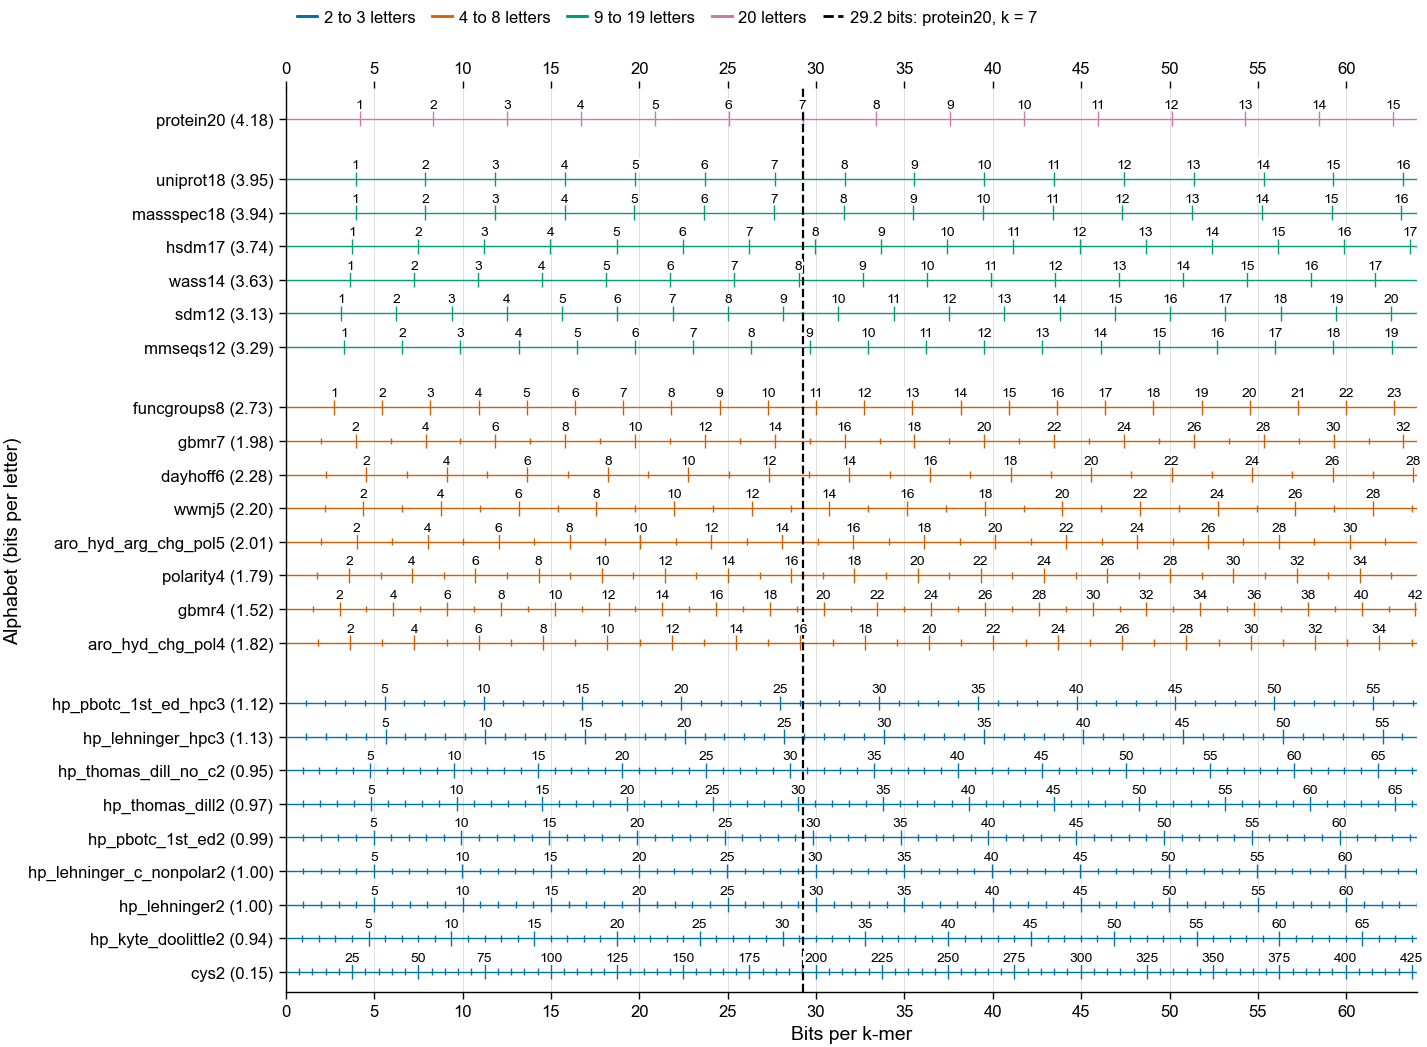

In [2]:
letters = pl.DataFrame(
    {
        "alphabet": ALPHABETS,
        "n_letters": [len(ou.KMERSEEK_ALPHABET_CLUSTERS[a]) for a in ALPHABETS],
        "bits_per_letter": [BITS_PER_LETTER[a] for a in ALPHABETS],
    }
).with_columns(
    pl.col("n_letters").log(2).alias("bits_if_letters_equally_common"),
    pl.struct("alphabet")
    .map_elements(
        lambda r: ou.ksize_for_bits(r["alphabet"], REFERENCE_BITS),
        return_dtype=pl.Int64,
    )
    .alias("k_for_protein20_k7_bits"),
)
letters.write_csv(DATA / "alphabet_bits_per_letter_human_mouse.tsv", separator="\t")
with pl.Config(tbl_rows=-1, tbl_width_chars=120, float_precision=3):
    print(letters)

LABEL_STEPS = (1, 2, 5, 10, 25, 50, 100)
MIN_LABEL_BITS = 2.3  # bits between labelled ticks, so two-digit labels do not touch
MIN_TICK_BITS = 0.4  # bits between small ticks, so they stay separate in print
K_LABEL_PT = 5


def first_step(steps, per_letter, smallest_gap):
    # The smallest step whose ticks sit at least smallest_gap bits apart.
    return next(s for s in steps if s * per_letter >= smallest_gap)


fig, ax = pf.figure(pf.TWO_COLUMN_MM, 135)
for alphabet in ALPHABETS:
    y = ROW_POSITIONS[alphabet]
    per_letter = BITS_PER_LETTER[alphabet]
    colour = GROUP_COLOURS[fu.alphabet_size_group(alphabet)]
    ax.hlines(y, 0, MAX_BITS, color=colour, linewidth=0.5, zorder=2)
    label_step = first_step(LABEL_STEPS, per_letter, MIN_LABEL_BITS)
    tick_step = first_step(LABEL_STEPS, per_letter, MIN_TICK_BITS)
    for k in range(tick_step, int(MAX_BITS / per_letter) + 1, tick_step):
        labelled = k % label_step == 0
        half_height = 0.22 if labelled else 0.1
        x = k * per_letter
        ax.vlines(
            x, y - half_height, y + half_height, color=colour, linewidth=0.5, zorder=2
        )
        if labelled:
            ax.text(
                x,
                y + 0.24,
                str(k),
                ha="center",
                va="bottom",
                fontsize=K_LABEL_PT,
                zorder=4,
                bbox=dict(facecolor="white", edgecolor="none", pad=0.3),
            )

ax.axvline(REFERENCE_BITS, color="black", linestyle="--", linewidth=0.8, zorder=3)
ax.set_yticks(
    list(ROW_POSITIONS.values()),
    [f"{a} ({BITS_PER_LETTER[a]:.2f})" for a in ROW_POSITIONS],
)
ax.set_ylim(-0.6, max(ROW_POSITIONS.values()) + 0.9)
ax.set_xlim(0, MAX_BITS)
ax.set_xticks(range(0, MAX_BITS + 1, 5))
ax.xaxis.grid(True, color="#d9d9d9", linewidth=0.3, zorder=0)
ax.tick_params(axis="x", top=True, labeltop=True)
ax.set_xlabel("Bits per k-mer")
ax.set_ylabel("Alphabet (bits per letter)")
handles = [
    Line2D(
        [], [], color=c, label=f"{lo} to {hi} letters" if lo != hi else f"{lo} letters"
    )
    for c, (lo, hi) in zip(GROUP_COLOURS, fu.ALPHABET_SIZE_GROUPS)
]
handles.append(
    Line2D(
        [],
        [],
        color="black",
        linestyle="--",
        label=f"{REFERENCE_BITS:.1f} bits: protein20, k = 7",
    )
)
fig.set_layout_engine(None)
fig.subplots_adjust(left=0.2, right=0.985, top=0.92, bottom=0.07)
fig.legend(
    handles=handles,
    loc="upper left",
    bbox_to_anchor=(0.2, 1.005),
    ncol=5,
    frameon=False,
)
pf.save(fig, FIGURES / "alphabet_ksize_ruler_by_bits_human_mouse")
print(FIGURES / "alphabet_ksize_ruler_by_bits_human_mouse.png")

## 2. The same lookup as a table

Each cell holds the k closest to the bits in that column. Only whole numbers of letters exist, so
k rarely lands exactly on the target. The colour shows the miss: white is an exact match, red
carries more bits than the column says and blue carries fewer. A miss can be as large as half of
one letter's bits, so alphabets with more bits per letter miss by more.

shape: (24, 12)
┌──────────────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┐
│ alphabet         ┆ 10 bits ┆ 15 bits ┆ 20 bits ┆ 25 bits ┆ 30 bits ┆ 35 bits ┆ 40 bits ┆ 45 bits ┆ 50 bits ┆ 55 bits ┆ 60 bits │
│ ---              ┆ ---     ┆ ---     ┆ ---     ┆ ---     ┆ ---     ┆ ---     ┆ ---     ┆ ---     ┆ ---     ┆ ---     ┆ ---     │
│ str              ┆ i64     ┆ i64     ┆ i64     ┆ i64     ┆ i64     ┆ i64     ┆ i64     ┆ i64     ┆ i64     ┆ i64     ┆ i64     │
╞══════════════════╪═════════╪═════════╪═════════╪═════════╪═════════╪═════════╪═════════╪═════════╪═════════╪═════════╪═════════╡
│ cys2             ┆ 67      ┆ 100     ┆ 133     ┆ 167     ┆ 200     ┆ 233     ┆ 267     ┆ 300     ┆ 334     ┆ 367     ┆ 400     │
│ hp_kyte_doolittl ┆ 11      ┆ 16      ┆ 21      ┆ 27      ┆ 32      ┆ 37      ┆ 43      ┆ 48      ┆ 53      ┆ 59      ┆ 64      │
│ e2               ┆         ┆         ┆         ┆         ┆       

figures/363/alphabet_ksize_lookup_table_by_bits_human_mouse.png


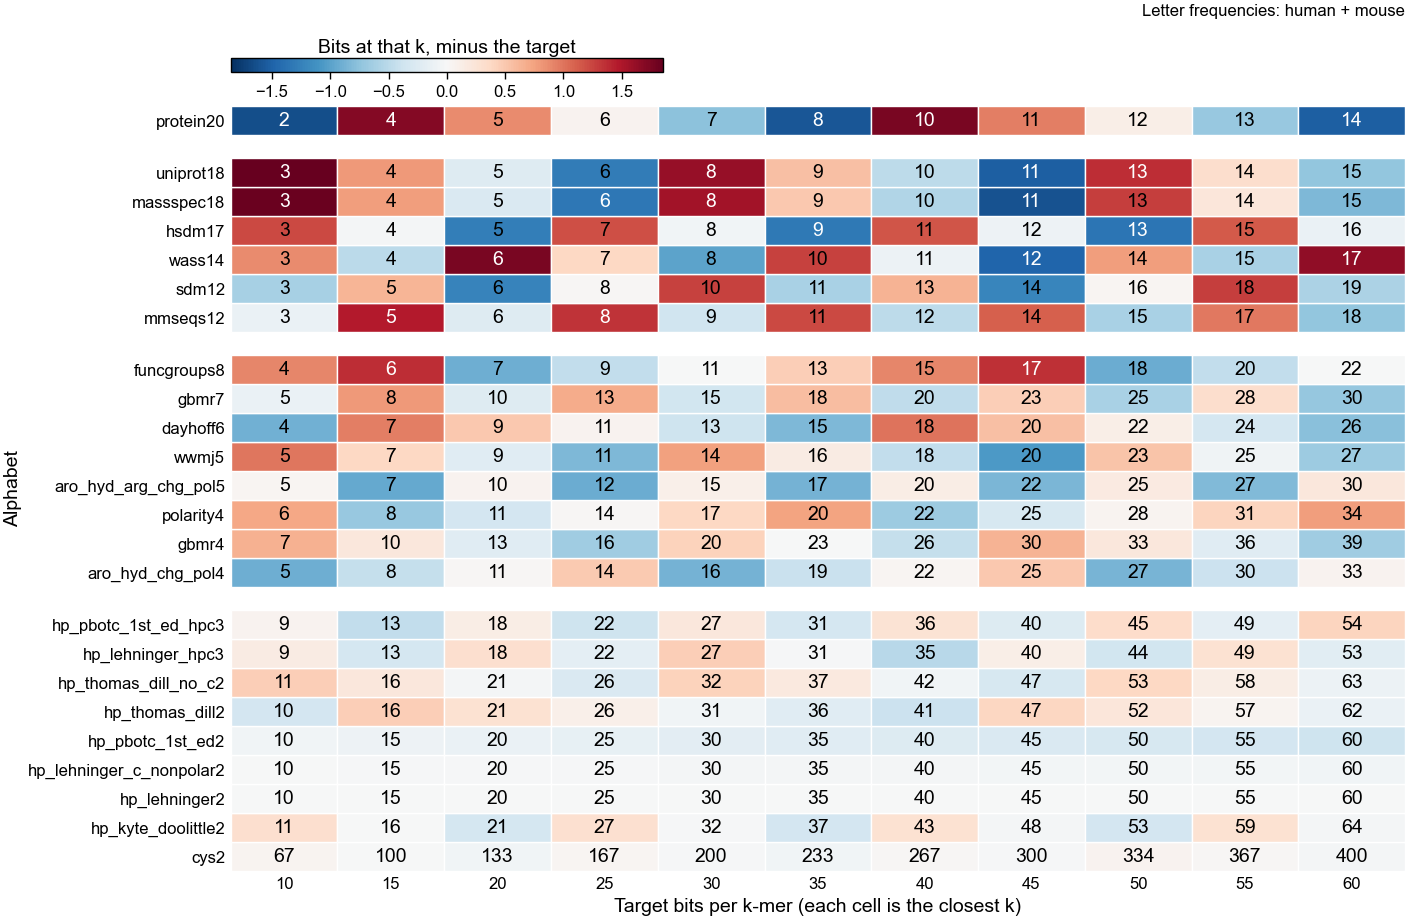

In [3]:
TARGET_BITS = list(range(10, 65, 5))


def lookup_by_bits(frequencies):
    # One row per alphabet and target bits: the closest k and how far it lands from the target.
    rows = []
    for a in ROW_POSITIONS:
        for t in TARGET_BITS:
            ksize = ou.ksize_for_bits(a, t, frequencies)
            rows.append(
                {
                    "alphabet": a,
                    "n_letters": len(ou.KMERSEEK_ALPHABET_CLUSTERS[a]),
                    "target_bits": t,
                    "ksize": ksize,
                    "bits_at_ksize": ou.bits_per_kmer(a, ksize, frequencies),
                }
            )
    return pl.DataFrame(rows).with_columns(
        (pl.col("bits_at_ksize") - pl.col("target_bits")).alias("bits_over_target")
    )


def print_lookup(lookup):
    # Print the k for each alphabet and target, then the three largest misses.
    wide = lookup.pivot(on="target_bits", index="alphabet", values="ksize")
    wide = wide.rename({str(t): f"{t} bits" for t in TARGET_BITS})
    with pl.Config(tbl_rows=-1, tbl_cols=-1, tbl_width_chars=130):
        print(wide)
    print(lookup.sort(pl.col("bits_over_target").abs(), descending=True).head(3))


def draw_lookup_table(lookup, frequency_source, stem):
    # Draw the table of closest k, coloured by how far each k lands from its column's target.
    largest_miss = lookup["bits_over_target"].abs().max()
    norm = mpl.colors.Normalize(-largest_miss, largest_miss)
    cmap = mpl.colormaps["RdBu_r"]
    fig, ax = pf.figure(pf.TWO_COLUMN_MM, 120)
    for row in lookup.iter_rows(named=True):
        x = TARGET_BITS.index(row["target_bits"])
        y = ROW_POSITIONS[row["alphabet"]]
        ax.add_patch(
            Rectangle(
                (x - 0.5, y - 0.5),
                1,
                1,
                facecolor=cmap(norm(row["bits_over_target"])),
                edgecolor="white",
                linewidth=0.5,
            )
        )
        dark_cell = abs(row["bits_over_target"]) > 0.7 * largest_miss
        ax.text(
            x,
            y,
            str(row["ksize"]),
            ha="center",
            va="center",
            color="white" if dark_cell else "black",
        )
    ax.set_xlim(-0.5, len(TARGET_BITS) - 0.5)
    ax.set_ylim(-0.5, max(ROW_POSITIONS.values()) + 0.5)
    ax.set_xticks(range(len(TARGET_BITS)), TARGET_BITS)
    ax.set_yticks(list(ROW_POSITIONS.values()), list(ROW_POSITIONS))
    ax.set_xlabel("Target bits per k-mer (each cell is the closest k)")
    ax.set_ylabel("Alphabet")
    ax.spines[["left", "bottom"]].set_visible(False)
    ax.tick_params(length=0)
    fig.set_layout_engine(None)
    fig.subplots_adjust(left=0.17, right=0.985, top=0.89, bottom=0.08)
    colour_key_ax = fig.add_axes([0.17, 0.925, 0.3, 0.015])
    fig.colorbar(
        mpl.cm.ScalarMappable(norm=norm, cmap=cmap),
        cax=colour_key_ax,
        orientation="horizontal",
        label="Bits at that k, minus the target",
    )
    colour_key_ax.xaxis.set_label_position("top")
    fig.text(
        0.985,
        0.998,
        f"Letter frequencies: {frequency_source}",
        ha="right",
        va="top",
        fontsize=mpl.rcParams["legend.fontsize"],
    )
    pf.save(fig, FIGURES / stem)
    print(FIGURES / f"{stem}.png")


lookup = lookup_by_bits(ou.AA_FREQUENCIES)
lookup.write_csv(DATA / "alphabet_ksize_lookup_by_bits_human_mouse.tsv", separator="\t")
print_lookup(lookup)
draw_lookup_table(
    lookup, "human + mouse", "alphabet_ksize_lookup_table_by_bits_human_mouse"
)

## 3. Does the lookup depend on which proteins set the letter frequencies?

This tests the decision rule from the top of the notebook. The human and mouse frequencies are
compared with the UHGP-90 values in
[notebook 300](300_mass_spec_peptide_source_lookup_uhgp90.ipynb), section 9, for the 20 alphabets
in both. Each k is the closest one to 29.2 bits, using that database's own bits per letter.

shape: (20, 6)
┌─────────────────────────┬─────────────────────────┬────────────────────────┬───────────────┬──────────┬──────────────┐
│ alphabet                ┆ bits_per_letter_human_m ┆ bits_per_letter_uhgp90 ┆ k_human_mouse ┆ k_uhgp90 ┆ k_difference │
│ ---                     ┆ ouse                    ┆ ---                    ┆ ---           ┆ ---      ┆ ---          │
│ str                     ┆ ---                     ┆ f64                    ┆ i64           ┆ i64      ┆ i64          │
│                         ┆ f64                     ┆                        ┆               ┆          ┆              │
╞═════════════════════════╪═════════════════════════╪════════════════════════╪═══════════════╪══════════╪══════════════╡
│ hp_kyte_doolittle2      ┆ 0.937                   ┆ 0.964                  ┆ 31            ┆ 30       ┆ -1           │
│ hp_thomas_dill_no_c2    ┆ 0.951                   ┆ 0.982                  ┆ 31            ┆ 30       ┆ -1           │
│ hp_thomas_dill2

figures/363/bits_per_letter_human_mouse_vs_uhgp90.png


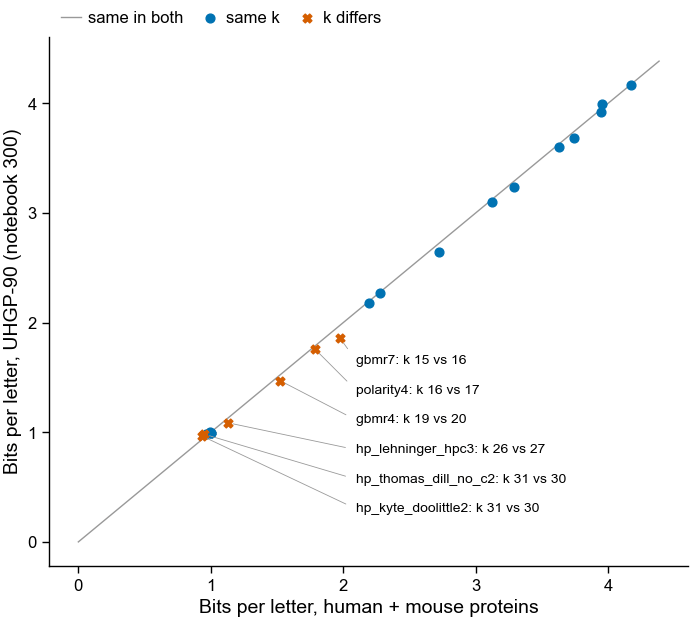

In [4]:
uhgp = pl.read_csv("300_data/settings_one_k_per_alphabet.tsv", separator="\t").select(
    "alphabet", pl.col("bits_per_position").alias("bits_per_letter_uhgp90")
)
both = (
    letters.select(
        "alphabet", pl.col("bits_per_letter").alias("bits_per_letter_human_mouse")
    )
    .join(uhgp, on="alphabet", how="inner")
    .with_columns(
        (pl.lit(REFERENCE_BITS) / pl.col("bits_per_letter_human_mouse"))
        .round()
        .cast(int)
        .alias("k_human_mouse"),
        (pl.lit(REFERENCE_BITS) / pl.col("bits_per_letter_uhgp90"))
        .round()
        .cast(int)
        .alias("k_uhgp90"),
    )
    .with_columns((pl.col("k_uhgp90") - pl.col("k_human_mouse")).alias("k_difference"))
    .sort("k_human_mouse", descending=True)
)
both.write_csv(DATA / "bits_per_letter_human_mouse_vs_uhgp90.tsv", separator="\t")
with pl.Config(tbl_rows=-1, tbl_width_chars=120, float_precision=3):
    print(both)
n_within_one = both.filter(pl.col("k_difference").abs() <= 1).height
print(f"{n_within_one} of {both.height} alphabets: k differs by at most 1")
print(f"{both.filter(pl.col('k_difference') == 0).height} of {both.height}: same k")


def draw_bits_comparison(
    table, other_bits, other_k, other_label, label_x, label_top, label_step, stem
):
    # Plot bits per letter in two protein sets, naming each alphabet whose k differs.
    fig, ax = pf.figure(pf.ONE_COLUMN_MM, 80)
    axis_limit = table["bits_per_letter_human_mouse"].max() * 1.05
    ax.plot(
        [0, axis_limit],
        [0, axis_limit],
        color=pf.GREY,
        linewidth=0.5,
        label="same in both",
    )
    for k_differs, marker, colour in (
        (False, "o", pf.OKABE_ITO["blue"]),
        (True, "X", pf.OKABE_ITO["vermillion"]),
    ):
        subset = table.filter((pl.col("k_difference") != 0) == k_differs)
        ax.scatter(
            subset["bits_per_letter_human_mouse"],
            subset[other_bits],
            s=10,
            marker=marker,
            color=colour,
            zorder=3,
            label="k differs" if k_differs else "same k",
        )
        if k_differs:
            by_bits = subset.sort("bits_per_letter_human_mouse", descending=True)
            for i, row in enumerate(by_bits.iter_rows(named=True)):
                ax.annotate(
                    f"{row['alphabet']}: k {row['k_human_mouse']} vs {row[other_k]}",
                    (row["bits_per_letter_human_mouse"], row[other_bits]),
                    xytext=(label_x, label_top - label_step * i),
                    textcoords="data",
                    fontsize=K_LABEL_PT,
                    va="center",
                    arrowprops=dict(
                        arrowstyle="-",
                        color=pf.GREY,
                        linewidth=0.3,
                        shrinkB=2,
                        relpos=(0, 0.5),
                    ),
                )
    ax.set_xlabel("Bits per letter, human + mouse proteins")
    ax.set_ylabel(f"Bits per letter, {other_label}")
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, frameon=False)
    pf.save(fig, FIGURES / stem)
    print(FIGURES / f"{stem}.png")


draw_bits_comparison(
    both,
    "bits_per_letter_uhgp90",
    "k_uhgp90",
    "UHGP-90 (notebook 300)",
    2.1,
    1.65,
    0.27,
    "bits_per_letter_human_mouse_vs_uhgp90",
)

## 4. Bits against k, one line per alphabet

Each line is one alphabet, and its slope is that alphabet's bits per letter. A steep line reaches
a given number of bits at a small k. To compare alphabets, go across at one height and read k off
the bottom axis at each line. Colour shows how many letters the alphabet has, with the same
colours as the ruler in section 1, and each line is named where it leaves the top of the plot.

The 2-letter hydrophobic/polar lines nearly overlap because their bits per letter run only from
0.94 to 1.00. `cys2` is named inside the plot, because at 0.15 bits per letter it never reaches
the top.

shape: (24, 3)
┌──────────────────────────┬───────────┬─────────────────┐
│ alphabet                 ┆ n_letters ┆ bits_per_letter │
│ ---                      ┆ ---       ┆ ---             │
│ str                      ┆ i64       ┆ f64             │
╞══════════════════════════╪═══════════╪═════════════════╡
│ protein20                ┆ 20        ┆ 4.177           │
│ uniprot18                ┆ 18        ┆ 3.951           │
│ massspec18               ┆ 18        ┆ 3.944           │
│ hsdm17                   ┆ 17        ┆ 3.742           │
│ wass14                   ┆ 14        ┆ 3.626           │
│ mmseqs12                 ┆ 12        ┆ 3.293           │
│ sdm12                    ┆ 12        ┆ 3.127           │
│ funcgroups8              ┆ 8         ┆ 2.727           │
│ dayhoff6                 ┆ 6         ┆ 2.278           │
│ wwmj5                    ┆ 5         ┆ 2.197           │
│ aro_hyd_arg_chg_pol5     ┆ 5         ┆ 2.007           │
│ gbmr7                    ┆ 7         ┆ 

figures/363/bits_vs_ksize_by_alphabet_human_mouse.png


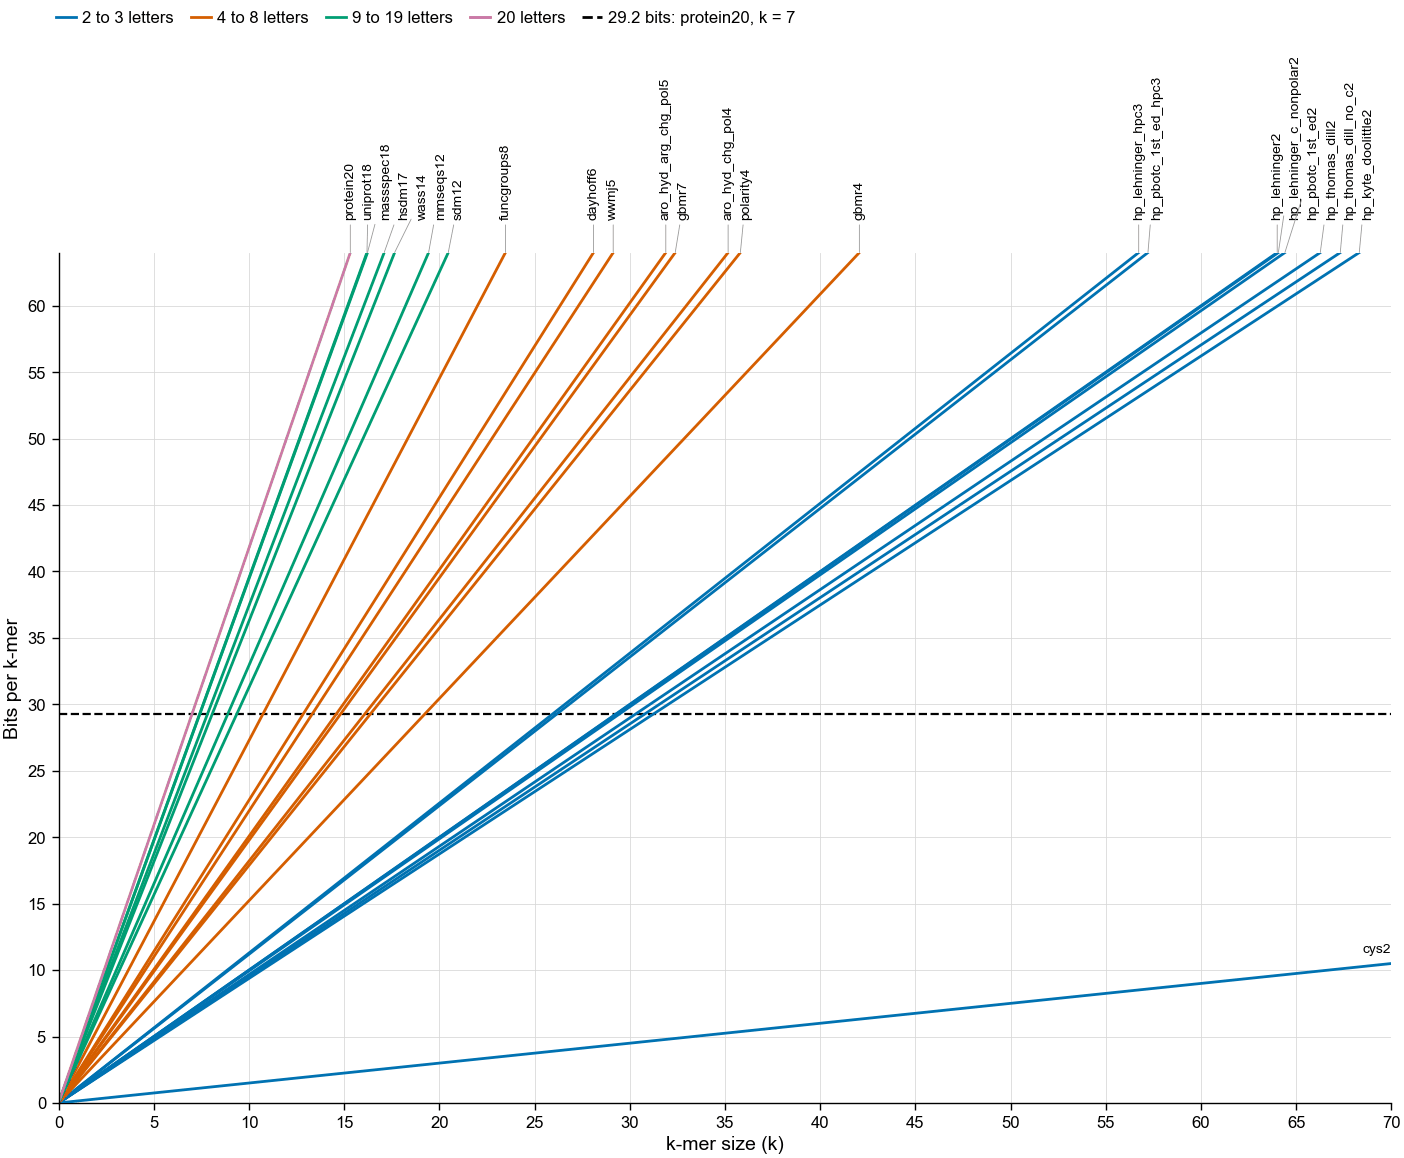

In [5]:
MAX_K = 70
LABEL_GAP_K = 0.95  # smallest space between two line labels, on the k axis


def spread_labels(positions, gap, highest):
    # Move sorted positions apart until they sit at least gap apart, staying at or below highest.
    spread = list(positions)
    for i in range(1, len(spread)):
        spread[i] = max(spread[i], spread[i - 1] + gap)
    spread[-1] = min(spread[-1], highest)
    for i in range(len(spread) - 2, -1, -1):
        spread[i] = min(spread[i], spread[i + 1] - gap)
    return spread


reach_top = sorted(
    (a for a in ALPHABETS if MAX_BITS / BITS_PER_LETTER[a] <= MAX_K),
    key=lambda a: MAX_BITS / BITS_PER_LETTER[a],
)
top_edge_k = [MAX_BITS / BITS_PER_LETTER[a] for a in reach_top]
label_k = spread_labels(top_edge_k, LABEL_GAP_K, MAX_K)

with pl.Config(tbl_rows=-1, tbl_width_chars=120, float_precision=3):
    print(
        letters.select("alphabet", "n_letters", "bits_per_letter").sort(
            "bits_per_letter", descending=True
        )
    )

fig, ax = pf.figure(pf.TWO_COLUMN_MM, 150)
ks = np.array([0, MAX_K])
for alphabet in ALPHABETS:
    ax.plot(
        ks,
        ks * BITS_PER_LETTER[alphabet],
        color=GROUP_COLOURS[fu.alphabet_size_group(alphabet)],
    )
for alphabet, end_k, text_k in zip(reach_top, top_edge_k, label_k):
    ax.annotate(
        alphabet,
        xy=(end_k, MAX_BITS),
        xytext=(text_k, MAX_BITS + 2.5),
        rotation=90,
        ha="center",
        va="bottom",
        fontsize=K_LABEL_PT,
        annotation_clip=False,
        arrowprops=dict(
            arrowstyle="-", color=pf.GREY, linewidth=0.3, shrinkA=0, shrinkB=0
        ),
    )
ax.text(
    MAX_K,
    MAX_K * BITS_PER_LETTER["cys2"] + 0.8,
    "cys2",
    ha="right",
    fontsize=K_LABEL_PT,
)
ax.axhline(REFERENCE_BITS, color="black", linestyle="--", linewidth=0.8, zorder=1)
ax.set_xlim(0, MAX_K)
ax.set_ylim(0, MAX_BITS)
ax.set_xticks(range(0, MAX_K + 1, 5))
ax.set_yticks(range(0, MAX_BITS + 1, 5))
ax.grid(True, color="#d9d9d9", linewidth=0.3, zorder=0)
ax.set_xlabel("k-mer size (k)")
ax.set_ylabel("Bits per k-mer")
fig.set_layout_engine(None)
fig.subplots_adjust(left=0.06, right=0.985, top=0.79, bottom=0.07)
fig.legend(
    handles=handles,
    loc="upper left",
    bbox_to_anchor=(0.05, 1.005),
    ncol=5,
    frameon=False,
)
pf.save(fig, FIGURES / "bits_vs_ksize_by_alphabet_human_mouse")
print(FIGURES / "bits_vs_ksize_by_alphabet_human_mouse.png")

## 5. Lines and rulers on one bits axis

Both panels share the bits axis, so one vertical line runs through both. Use panel a to see the
relationship: each line is one alphabet, and a steeper line means fewer bits per letter, so that
alphabet needs a larger k for the same bits. Use panel b to read the exact k: pick the bits, go
straight down, and read the number on each ruler.

Rows run from the fewest bits per letter at the top to the most at the bottom, the same order as
the lines in panel a. The dashed line is protein20 at k = 7.

shape: (24, 5)
┌──────────────────────────┬───────────┬─────────────────┬─────────────────────┬──────────────┐
│ alphabet                 ┆ n_letters ┆ bits_per_letter ┆ k_at_reference_bits ┆ k_at_64_bits │
│ ---                      ┆ ---       ┆ ---             ┆ ---                 ┆ ---          │
│ str                      ┆ i64       ┆ f64             ┆ i64                 ┆ i64          │
╞══════════════════════════╪═══════════╪═════════════════╪═════════════════════╪══════════════╡
│ cys2                     ┆ 2         ┆ 0.150           ┆ 195                 ┆ 427          │
│ hp_kyte_doolittle2       ┆ 2         ┆ 0.937           ┆ 31                  ┆ 68           │
│ hp_thomas_dill_no_c2     ┆ 2         ┆ 0.951           ┆ 31                  ┆ 67           │
│ hp_thomas_dill2          ┆ 2         ┆ 0.966           ┆ 30                  ┆ 66           │
│ hp_pbotc_1st_ed2         ┆ 2         ┆ 0.994           ┆ 29                  ┆ 64           │
│ hp_lehninger_c_nonpolar

figures/363/ksize_by_bits_lines_and_rulers_human_mouse.png


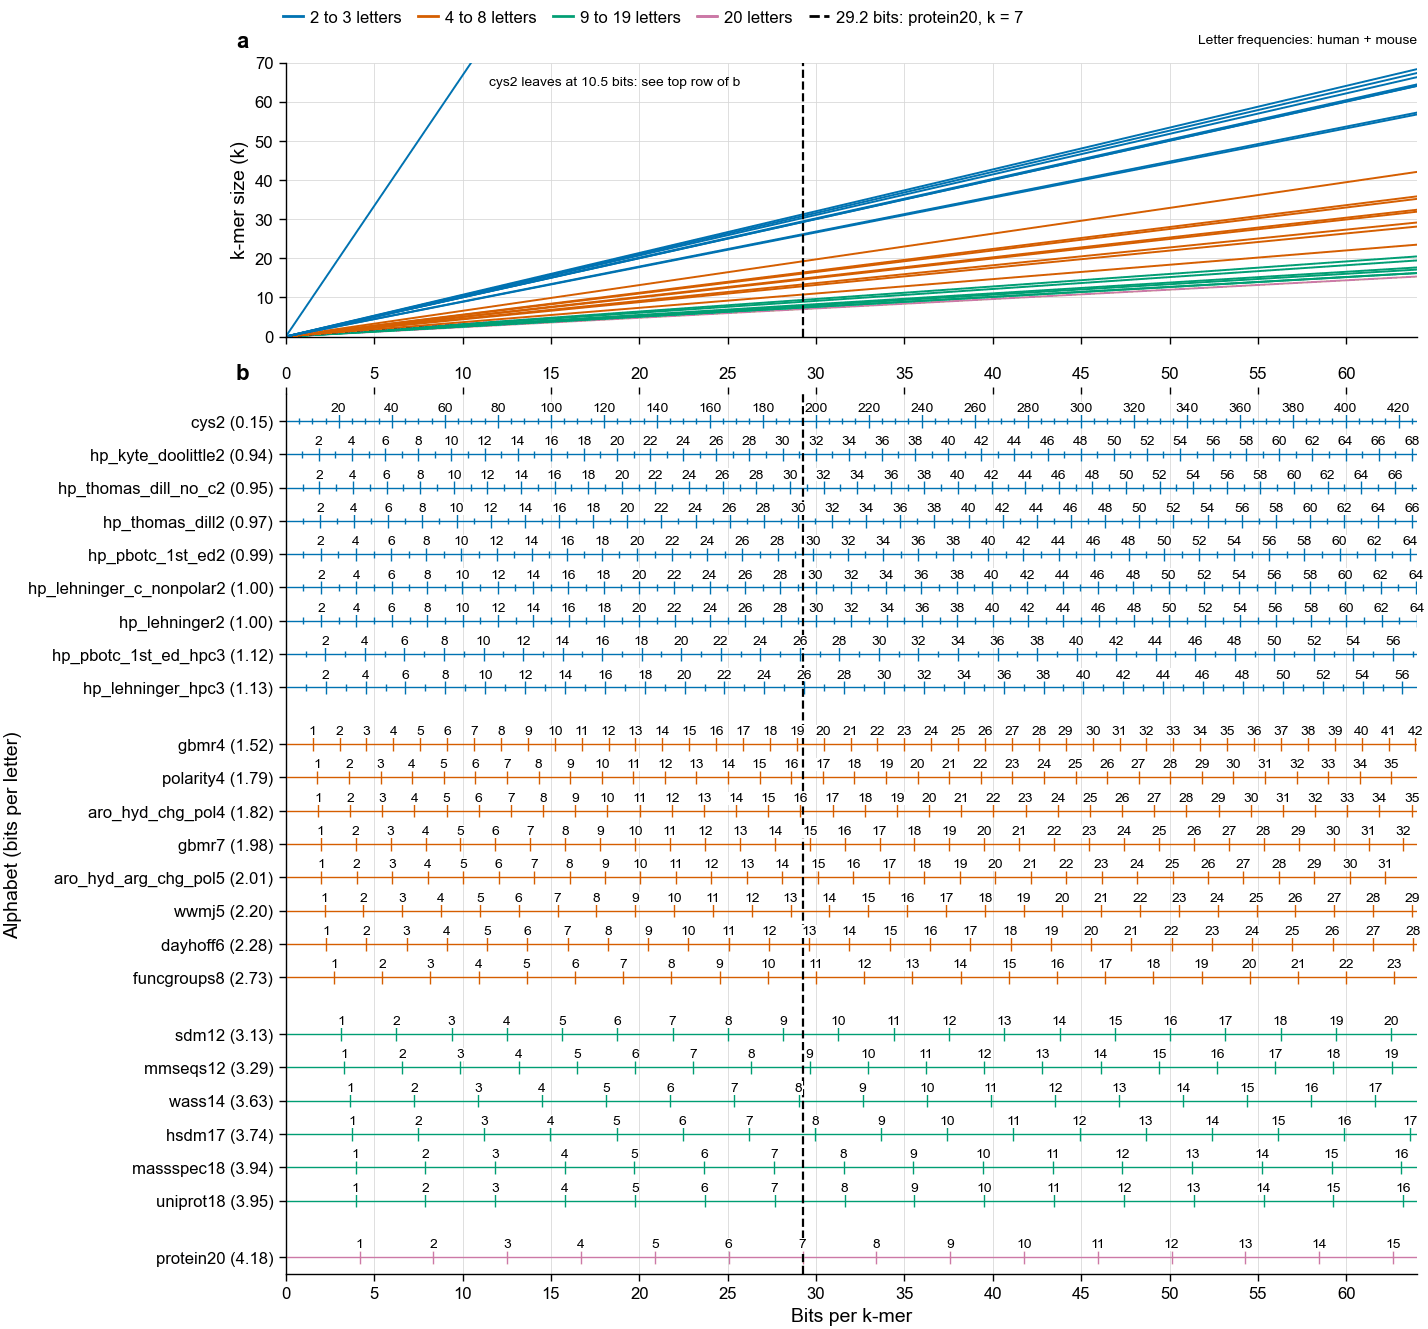

In [6]:
COMBINED_LABEL_STEPS = (1, 2, 5, 10, 20)
MIN_COMBINED_LABEL_BITS = (
    1.5  # bits between labelled ticks, so labels do not touch at 5 pt
)
GROUP_GAP_ROWS = 0.7  # extra blank rows between letter-count groups
LINE_PANEL_MM = 38
RULER_PANEL_MM = 122
FIGURE_MM = 170


def ruler_rows(bits_per_letter):
    # Rows from most bits per letter (row 0, bottom) to fewest, with a gap between groups.
    rows = {}
    y = 0.0
    previous_group = None
    for alphabet in sorted(ALPHABETS, key=lambda a: -bits_per_letter[a]):
        group = fu.alphabet_size_group(alphabet)
        if previous_group is not None and group != previous_group:
            y += GROUP_GAP_ROWS
        rows[alphabet] = y
        previous_group = group
        y += 1
    return rows


def draw_rulers(ax, bits_per_letter, rows):
    # One ruler per alphabet, with a tick at each whole k and a number on the larger ticks.
    for alphabet, y in rows.items():
        per_letter = bits_per_letter[alphabet]
        colour = GROUP_COLOURS[fu.alphabet_size_group(alphabet)]
        ax.hlines(y, 0, MAX_BITS, color=colour, linewidth=0.5, zorder=2)
        label_step = first_step(
            COMBINED_LABEL_STEPS, per_letter, MIN_COMBINED_LABEL_BITS
        )
        tick_step = first_step(COMBINED_LABEL_STEPS, per_letter, MIN_TICK_BITS)
        for k in range(tick_step, int(MAX_BITS / per_letter) + 1, tick_step):
            labelled = k % label_step == 0
            half_height = 0.2 if labelled else 0.1
            x = k * per_letter
            ax.vlines(
                x,
                y - half_height,
                y + half_height,
                color=colour,
                linewidth=0.5,
                zorder=2,
            )
            if labelled:
                ax.text(
                    x,
                    y + 0.2,
                    str(k),
                    ha="center",
                    va="bottom",
                    fontsize=K_LABEL_PT,
                    zorder=4,
                    bbox=dict(facecolor="white", edgecolor="none", pad=0.2),
                )
    ax.set_yticks(
        list(rows.values()), [f"{a} ({bits_per_letter[a]:.2f})" for a in rows]
    )
    ax.set_ylim(-0.5, max(rows.values()) + 0.8)
    ax.tick_params(axis="x", top=True, labeltop=True)
    ax.set_xlabel("Bits per k-mer")
    ax.set_ylabel("Alphabet (bits per letter)")


def draw_lines_and_rulers(bits_per_letter, frequency_source, stem):
    # Stack lines over rulers on one bits axis: relationship above, exact k below.
    reference_bits = PROTEIN_K * bits_per_letter["protein20"]
    rows = ruler_rows(bits_per_letter)
    fig, (line_ax, ruler_ax) = pf.figure(
        pf.TWO_COLUMN_MM,
        FIGURE_MM,
        nrows=2,
        sharex=True,
        gridspec_kw={"height_ratios": [LINE_PANEL_MM, RULER_PANEL_MM]},
    )
    bits = np.array([0, MAX_BITS])
    for alphabet in rows:
        line_ax.plot(
            bits,
            bits / bits_per_letter[alphabet],
            color=GROUP_COLOURS[fu.alphabet_size_group(alphabet)],
            linewidth=0.7,
        )
    leaves_at = MAX_K * bits_per_letter["cys2"]
    line_ax.text(
        leaves_at + 1,
        MAX_K - 5,
        f"cys2 leaves at {leaves_at:.1f} bits: see top row of b",
        va="center",
        fontsize=K_LABEL_PT,
    )
    line_ax.set_ylim(0, MAX_K)
    line_ax.set_yticks(range(0, MAX_K + 1, 10))
    line_ax.set_ylabel("k-mer size (k)")
    line_ax.yaxis.grid(True, color="#d9d9d9", linewidth=0.3, zorder=0)
    draw_rulers(ruler_ax, bits_per_letter, rows)
    for ax in (line_ax, ruler_ax):
        ax.axvline(
            reference_bits, color="black", linestyle="--", linewidth=0.8, zorder=3
        )
        ax.xaxis.grid(True, color="#d9d9d9", linewidth=0.3, zorder=0)
    ruler_ax.set_xlim(0, MAX_BITS)
    ruler_ax.set_xticks(range(0, MAX_BITS + 1, 5))
    fig.set_layout_engine(None)
    fig.subplots_adjust(left=0.2, right=0.985, top=0.955, bottom=0.05, hspace=0.1)
    reference_handle = Line2D(
        [],
        [],
        color="black",
        linestyle="--",
        label=f"{reference_bits:.1f} bits: protein20, k = {PROTEIN_K}",
    )
    fig.legend(
        handles=handles[:-1] + [reference_handle],
        loc="upper left",
        bbox_to_anchor=(0.19, 1.003),
        ncol=5,
        frameon=False,
    )
    fig.text(
        0.985,
        0.967,
        f"Letter frequencies: {frequency_source}",
        ha="right",
        va="bottom",
        fontsize=K_LABEL_PT,
    )
    for ax, letter in zip((line_ax, ruler_ax), "ab"):
        pf.panel_label(ax, letter)
    pf.save(fig, FIGURES / stem)
    print(FIGURES / f"{stem}.png")


with pl.Config(tbl_rows=-1, tbl_width_chars=120, float_precision=3):
    print(
        letters.select("alphabet", "n_letters", "bits_per_letter")
        .with_columns(
            pl.col("alphabet")
            .map_elements(
                lambda a: ou.ksize_for_bits(a, REFERENCE_BITS), return_dtype=pl.Int64
            )
            .alias("k_at_reference_bits"),
            pl.col("alphabet")
            .map_elements(
                lambda a: ou.ksize_for_bits(a, MAX_BITS), return_dtype=pl.Int64
            )
            .alias(f"k_at_{MAX_BITS}_bits"),
        )
        .sort("bits_per_letter")
    )
draw_lines_and_rulers(
    BITS_PER_LETTER, "human + mouse", "ksize_by_bits_lines_and_rulers_human_mouse"
)

## 6. The same lookup with Swiss-Prot letter frequencies

The sections above use human and mouse proteins. Swiss-Prot covers reviewed proteins from all
kingdoms of life, so here its amino acid counts replace them. Counts come from release 2026_03:
575,748 sequences and 209,008,777 standard residues, counted by
`scripts/count_swissprot_amino_acids.py`. The 9,066 X, U, B, Z and O residues are left out, as they
were for human and mouse.

This comparison was added after the results above, so it is a second check, not the planned test.
The rule is unchanged: the k for 29.2 bits may differ by at most 1.

shape: (20, 5)
┌────────────┬──────────┬───────────┬─────────────┬────────────────────────────┐
│ amino_acid ┆ count    ┆ swissprot ┆ human_mouse ┆ swissprot_over_human_mouse │
│ ---        ┆ ---      ┆ ---       ┆ ---         ┆ ---                        │
│ str        ┆ i64      ┆ f64       ┆ f64         ┆ f64                        │
╞════════════╪══════════╪═══════════╪═════════════╪════════════════════════════╡
│ C          ┆ 2904415  ┆ 0.0139    ┆ 0.0215      ┆ 0.6457                     │
│ P          ┆ 9932649  ┆ 0.0475    ┆ 0.0617      ┆ 0.7707                     │
│ S          ┆ 13933222 ┆ 0.0667    ┆ 0.0827      ┆ 0.8063                     │
│ Q          ┆ 8221407  ┆ 0.0393    ┆ 0.0484      ┆ 0.8128                     │
│ H          ┆ 4764667  ┆ 0.0228    ┆ 0.0259      ┆ 0.8787                     │
│ W          ┆ 2312297  ┆ 0.0111    ┆ 0.0119      ┆ 0.9265                     │
│ E          ┆ 14032286 ┆ 0.0671    ┆ 0.0722      ┆ 0.9305                     │
│ L          

figures/363/bits_per_letter_human_mouse_vs_swissprot.png


figures/363/alphabet_ksize_lookup_table_by_bits_swissprot.png


figures/363/ksize_by_bits_lines_and_rulers_swissprot.png


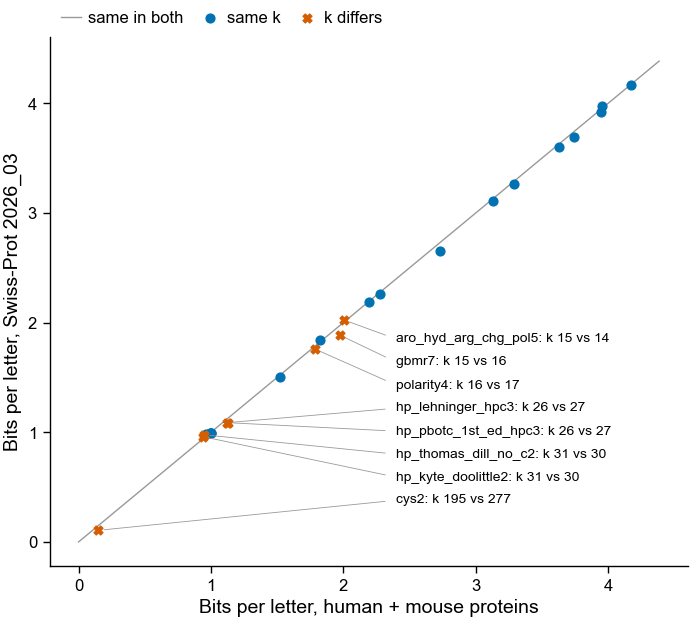

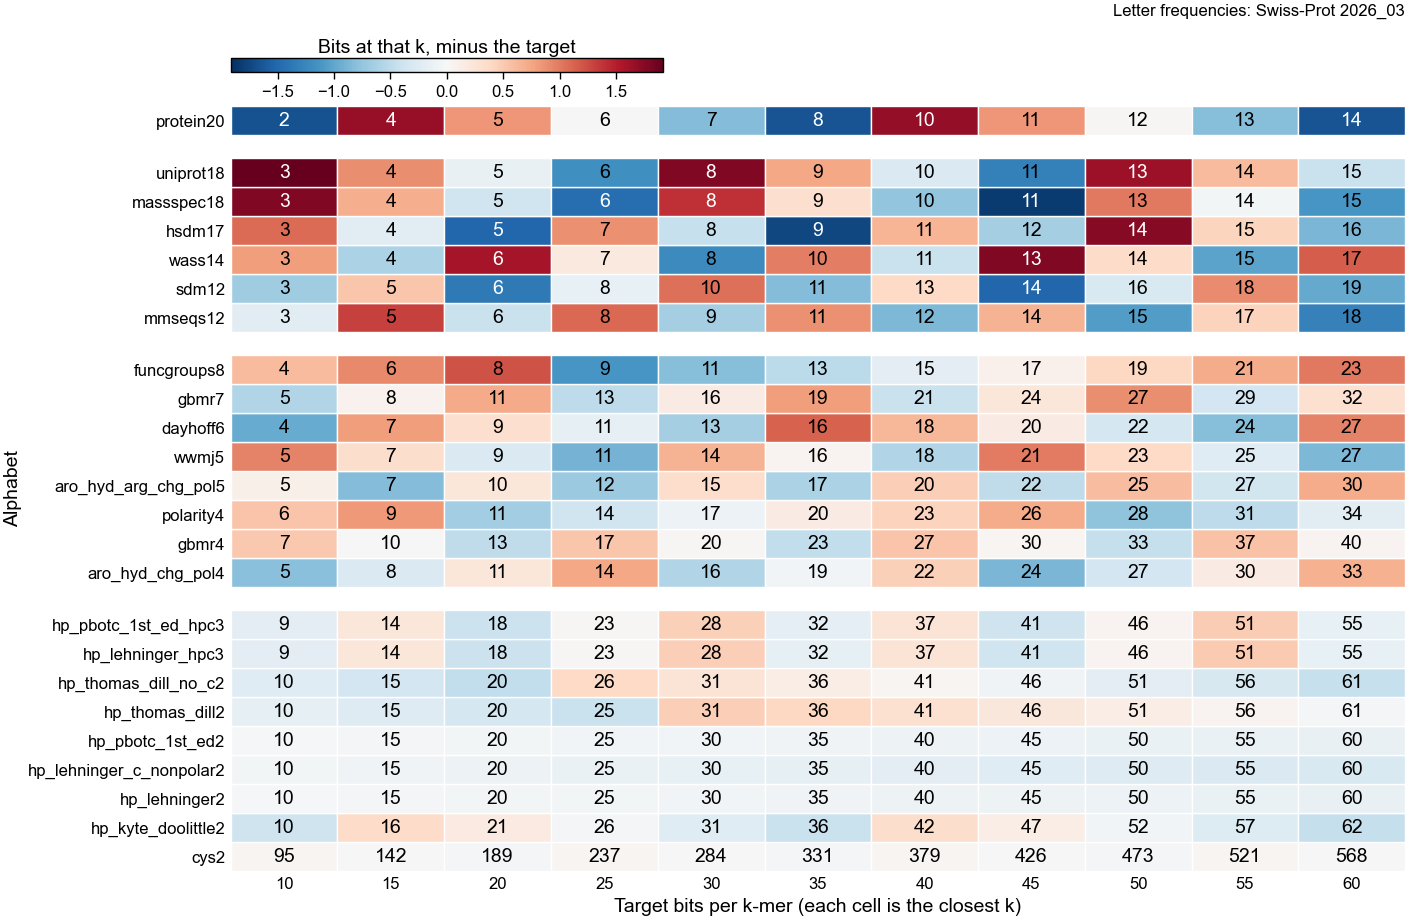

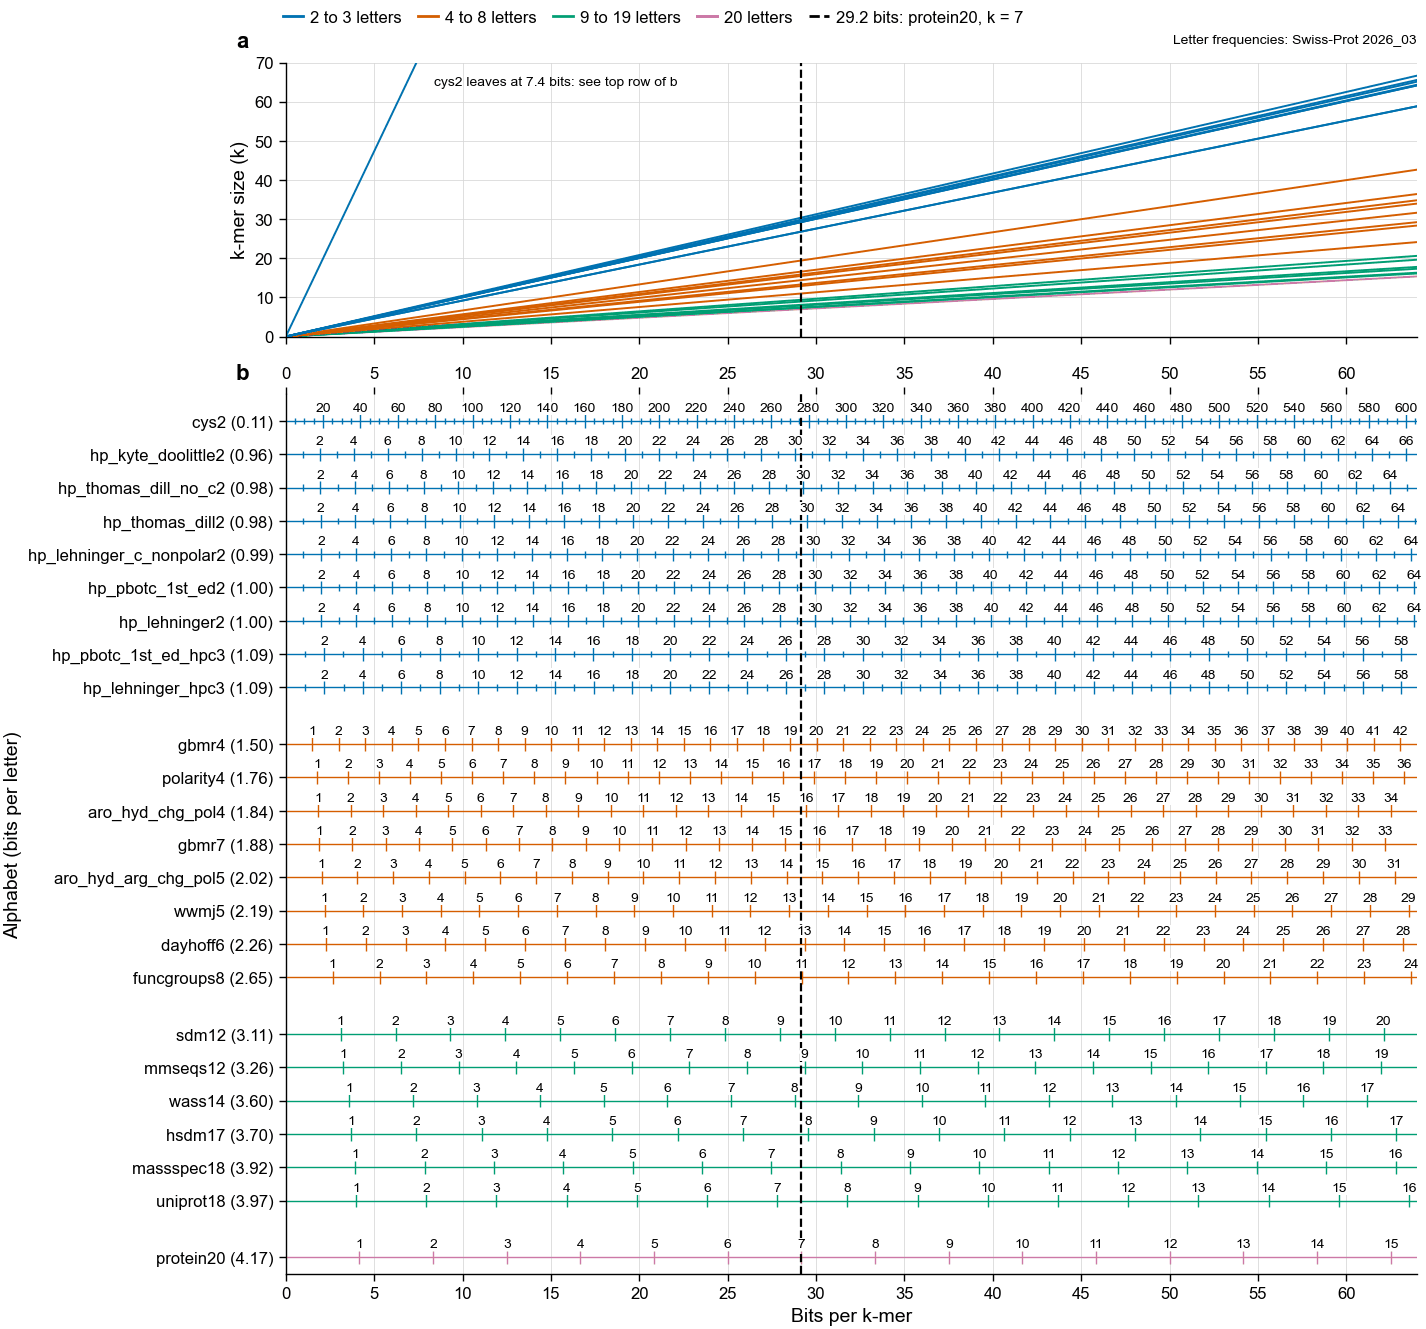

In [7]:
SWISSPROT = ou.SWISSPROT_AA_FREQUENCIES
SWISSPROT_LABEL = "Swiss-Prot 2026_03"
amino_acids = (
    pl.read_csv(DATA / "swissprot_2026_03_amino_acid_counts.tsv", separator="\t")
    .rename({"frequency": "swissprot"})
    .with_columns(
        pl.col("amino_acid")
        .map_elements(lambda aa: ou.AA_FREQUENCIES[aa], return_dtype=pl.Float64)
        .alias("human_mouse")
    )
    .with_columns(
        (pl.col("swissprot") / pl.col("human_mouse")).alias(
            "swissprot_over_human_mouse"
        )
    )
    .sort("swissprot_over_human_mouse")
)
with pl.Config(tbl_rows=-1, tbl_width_chars=120, float_precision=4):
    print(amino_acids)

swissprot_letters = (
    pl.DataFrame(
        {
            "alphabet": ALPHABETS,
            "bits_per_letter_human_mouse": [BITS_PER_LETTER[a] for a in ALPHABETS],
            "bits_per_letter_swissprot": [
                ou.entropy_per_symbol(a, SWISSPROT) for a in ALPHABETS
            ],
            "k_human_mouse": [ou.ksize_for_bits(a, REFERENCE_BITS) for a in ALPHABETS],
            "k_swissprot": [
                ou.ksize_for_bits(a, REFERENCE_BITS, SWISSPROT) for a in ALPHABETS
            ],
        }
    )
    .with_columns(
        (pl.col("k_swissprot") - pl.col("k_human_mouse")).alias("k_difference"),
        pl.col("alphabet")
        .is_in(both["alphabet"].to_list())
        .alias("in_uhgp90_comparison"),
    )
    .sort("k_human_mouse", descending=True)
)
swissprot_letters.write_csv(
    DATA / "bits_per_letter_human_mouse_vs_swissprot.tsv", separator="\t"
)
with pl.Config(tbl_rows=-1, tbl_width_chars=130, float_precision=3):
    print(swissprot_letters)

shared = swissprot_letters.filter(pl.col("in_uhgp90_comparison"))
for name, table in (
    ("all alphabets", swissprot_letters),
    ("UHGP-90's alphabets", shared),
):
    n_same = table.filter(pl.col("k_difference") == 0).height
    n_within_one = table.filter(pl.col("k_difference").abs() <= 1).height
    print(
        f"{name}: same k {n_same} of {table.height}; within 1 {n_within_one} of {table.height}"
    )

swissprot_lookup = lookup_by_bits(SWISSPROT)
swissprot_lookup.write_csv(
    DATA / "alphabet_ksize_lookup_by_bits_swissprot.tsv", separator="\t"
)
print_lookup(swissprot_lookup)
changed = swissprot_lookup.join(
    lookup, on=["alphabet", "target_bits"], suffix="_human_mouse"
)
changed = changed.with_columns(
    (pl.col("ksize") - pl.col("ksize_human_mouse")).alias("k_change")
)
without_cys2 = changed.filter(pl.col("alphabet") != "cys2")
print(
    f"{changed.filter(pl.col('k_change') != 0).height} of {changed.height} table cells change"
)
print(f"largest change without cys2: {without_cys2['k_change'].abs().max()}")
print(f"largest change for cys2: {changed['k_change'].abs().max()}")

draw_bits_comparison(
    swissprot_letters,
    "bits_per_letter_swissprot",
    "k_swissprot",
    SWISSPROT_LABEL,
    2.4,
    1.85,
    0.21,
    "bits_per_letter_human_mouse_vs_swissprot",
)
draw_lookup_table(
    swissprot_lookup, SWISSPROT_LABEL, "alphabet_ksize_lookup_table_by_bits_swissprot"
)
draw_lines_and_rulers(
    {a: ou.entropy_per_symbol(a, SWISSPROT) for a in ALPHABETS},
    SWISSPROT_LABEL,
    "ksize_by_bits_lines_and_rulers_swissprot",
)

# Summary and Conclusions

## Background

kmerseek's alphabets carry different amounts of information per letter, so the same k means
different things in each. This notebook gives the k for any number of bits per k-mer, across all
24 alphabets in kmerseek 0.5.0.

## Summary and Conclusions

* kmerseek's 24 alphabets carry 0.15 to 4.18 bits per letter, so matching protein20 at k = 7
  (29.2 bits) takes k = 7 to k = 195.
* `hp_lehninger2` at k = 29 carries 29.0 bits against protein20's 29.2 at k = 7, because each
  hydrophobic/polar letter carries 1.00 bit.
* Assuming equally common letters overstates `gbmr7` by 42%: 2.81 bits per letter against a
  measured 1.98.
* Rounding to a whole k misses the table's targets by at most 1.85 bits (`uniprot18` at 10 bits)
  and by at most 0.46 bits for 2-letter alphabets.
* The k for 29.2 bits matches between human + mouse and UHGP-90 for 14 of 20 alphabets and is
  off by 1 for the other 6.
* The k for 29.2 bits stays within 1 between human + mouse and Swiss-Prot for 23 of 24 alphabets.
* `cys2` needs k = 277 for 29.2 bits on Swiss-Prot against k = 195 on human + mouse, because
  cysteine is 1.39% of Swiss-Prot residues against 2.15%.

**Decision.** The rule at the top passes: 20 of 20 alphabets are within 1 of each other, and that
holds again for those 20 on Swiss-Prot. Reuse one lookup for those alphabets, and expect k to move
by up to 1 at 29.2 bits and up to 2 anywhere from 10 to 60 bits. Do not reuse it for `cys2`:
UHGP-90 has no `cys2` value, and Swiss-Prot shows its k depends on the cysteine content of the
database searched, so calculate it for each database. The other three alphabets missing from
UHGP-90 stay within 1 on Swiss-Prot.

## Analysis Details

Bits per letter is the Shannon entropy of each alphabet's letters. Each letter's frequency is the
sum of the human and mouse frequencies of its residues. The closest k is bits / bits per letter,
rounded, with a minimum of 1. Section 3 repeats the k calculation with the UHGP-90 values from
notebook 300.

## Supplementary Information

- Tables: `363_data/alphabet_bits_per_letter_human_mouse.tsv`,
  `363_data/alphabet_ksize_lookup_by_bits_human_mouse.tsv`,
  `363_data/bits_per_letter_human_mouse_vs_uhgp90.tsv`,
  `363_data/swissprot_2026_03_amino_acid_counts.tsv`,
  `363_data/bits_per_letter_human_mouse_vs_swissprot.tsv`,
  `363_data/alphabet_ksize_lookup_by_bits_swissprot.tsv`.
- Figures: `figures/363/alphabet_ksize_ruler_by_bits_human_mouse.png`,
  `figures/363/alphabet_ksize_lookup_table_by_bits_human_mouse.png`,
  `figures/363/bits_per_letter_human_mouse_vs_uhgp90.png`,
  `figures/363/bits_vs_ksize_by_alphabet_human_mouse.png`,
  `figures/363/ksize_by_bits_lines_and_rulers_human_mouse.png`,
  `figures/363/bits_per_letter_human_mouse_vs_swissprot.png`,
  `figures/363/alphabet_ksize_lookup_table_by_bits_swissprot.png`,
  `figures/363/ksize_by_bits_lines_and_rulers_swissprot.png`.
- Limits: positions are treated as independent, so real k-mers carry fewer bits than shown. The
  figures do not say whether a k can seed in a given protein. `cys2` is the clearest case: k = 195
  is longer than many proteins.
- The human + mouse frequencies count all 312,203 GENCODE translations, so a gene with many
  transcripts counts many times. The Swiss-Prot frequencies count each reviewed entry once.
- Four alphabets are new since notebook 300's table and have no UHGP-90 value here: `cys2`,
  `hp_pbotc_1st_ed_hpc3`, `aro_hyd_chg_pol4` and `aro_hyd_arg_chg_pol5`.

## References

- kmerseek 0.5.0, seanome/kmerseek main 0643254, `src/rust/alphabets.rs`.
- [Notebook 300](300_mass_spec_peptide_source_lookup_uhgp90.ipynb), section 9.
- UniProtKB/Swiss-Prot release 2026_03, `uniprot_sprot.fasta.gz`.

In [8]:
summary_md = r"""
# Summary and Conclusions

## Background

kmerseek's alphabets carry different amounts of information per letter, so the same k means
different things in each. This notebook gives the k for any number of bits per k-mer, across all
24 alphabets in kmerseek 0.5.0.

## Summary and Conclusions

* kmerseek's 24 alphabets carry 0.15 to 4.18 bits per letter, so matching protein20 at k = 7
  (29.2 bits) takes k = 7 to k = 195.
* `hp_lehninger2` at k = 29 carries 29.0 bits against protein20's 29.2 at k = 7, because each
  hydrophobic/polar letter carries 1.00 bit.
* Assuming equally common letters overstates `gbmr7` by 42%: 2.81 bits per letter against a
  measured 1.98.
* Rounding to a whole k misses the table's targets by at most 1.85 bits (`uniprot18` at 10 bits)
  and by at most 0.46 bits for 2-letter alphabets.
* The k for 29.2 bits matches between human + mouse and UHGP-90 for 14 of 20 alphabets and is
  off by 1 for the other 6.
* The k for 29.2 bits stays within 1 between human + mouse and Swiss-Prot for 23 of 24 alphabets.
* `cys2` needs k = 277 for 29.2 bits on Swiss-Prot against k = 195 on human + mouse, because
  cysteine is 1.39% of Swiss-Prot residues against 2.15%.

**Decision.** The rule at the top passes: 20 of 20 alphabets are within 1 of each other, and that
holds again for those 20 on Swiss-Prot. Reuse one lookup for those alphabets, and expect k to move
by up to 1 at 29.2 bits and up to 2 anywhere from 10 to 60 bits. Do not reuse it for `cys2`:
UHGP-90 has no `cys2` value, and Swiss-Prot shows its k depends on the cysteine content of the
database searched, so calculate it for each database. The other three alphabets missing from
UHGP-90 stay within 1 on Swiss-Prot.

## Analysis Details

Bits per letter is the Shannon entropy of each alphabet's letters. Each letter's frequency is the
sum of the human and mouse frequencies of its residues. The closest k is bits / bits per letter,
rounded, with a minimum of 1. Section 3 repeats the k calculation with the UHGP-90 values from
notebook 300.

## Supplementary Information

- Tables: `363_data/alphabet_bits_per_letter_human_mouse.tsv`,
  `363_data/alphabet_ksize_lookup_by_bits_human_mouse.tsv`,
  `363_data/bits_per_letter_human_mouse_vs_uhgp90.tsv`,
  `363_data/swissprot_2026_03_amino_acid_counts.tsv`,
  `363_data/bits_per_letter_human_mouse_vs_swissprot.tsv`,
  `363_data/alphabet_ksize_lookup_by_bits_swissprot.tsv`.
- Figures: `figures/363/alphabet_ksize_ruler_by_bits_human_mouse.png`,
  `figures/363/alphabet_ksize_lookup_table_by_bits_human_mouse.png`,
  `figures/363/bits_per_letter_human_mouse_vs_uhgp90.png`,
  `figures/363/bits_vs_ksize_by_alphabet_human_mouse.png`,
  `figures/363/ksize_by_bits_lines_and_rulers_human_mouse.png`,
  `figures/363/bits_per_letter_human_mouse_vs_swissprot.png`,
  `figures/363/alphabet_ksize_lookup_table_by_bits_swissprot.png`,
  `figures/363/ksize_by_bits_lines_and_rulers_swissprot.png`.
- Limits: positions are treated as independent, so real k-mers carry fewer bits than shown. The
  figures do not say whether a k can seed in a given protein. `cys2` is the clearest case: k = 195
  is longer than many proteins.
- The human + mouse frequencies count all 312,203 GENCODE translations, so a gene with many
  transcripts counts many times. The Swiss-Prot frequencies count each reviewed entry once.
- Four alphabets are new since notebook 300's table and have no UHGP-90 value here: `cys2`,
  `hp_pbotc_1st_ed_hpc3`, `aro_hyd_chg_pol4` and `aro_hyd_arg_chg_pol5`.

## References

- kmerseek 0.5.0, seanome/kmerseek main 0643254, `src/rust/alphabets.rs`.
- [Notebook 300](300_mass_spec_peptide_source_lookup_uhgp90.ipynb), section 9.
- UniProtKB/Swiss-Prot release 2026_03, `uniprot_sprot.fasta.gz`.
"""
print(summary_md)


# Summary and Conclusions

## Background

kmerseek's alphabets carry different amounts of information per letter, so the same k means
different things in each. This notebook gives the k for any number of bits per k-mer, across all
24 alphabets in kmerseek 0.5.0.

## Summary and Conclusions

* kmerseek's 24 alphabets carry 0.15 to 4.18 bits per letter, so matching protein20 at k = 7
  (29.2 bits) takes k = 7 to k = 195.
* `hp_lehninger2` at k = 29 carries 29.0 bits against protein20's 29.2 at k = 7, because each
  hydrophobic/polar letter carries 1.00 bit.
* Assuming equally common letters overstates `gbmr7` by 42%: 2.81 bits per letter against a
  measured 1.98.
* Rounding to a whole k misses the table's targets by at most 1.85 bits (`uniprot18` at 10 bits)
  and by at most 0.46 bits for 2-letter alphabets.
* The k for 29.2 bits matches between human + mouse and UHGP-90 for 14 of 20 alphabets and is
  off by 1 for the other 6.
* The k for 29.2 bits stays within 1 between human + mouse